# QMSS5074GR: Projects in Advanced Machine Learning
## Project 1: World Happiness Classification

---

### Group Information

Fill this in before you submit.

**Group number:** 4

| Full Name |  UNI  |
|-----------|-------|
| Kejia Gu  | kg3222|

**Public GitHub repository URL:** https://github.com/kg3222-nav/QMSSGR5074-group4-repo

## How to Complete and Submit This Project

**Due: Monday, October 19, 2026**

This notebook is the whole assignment. Everything you need to do is written here, and the completed notebook is the only thing you submit. Keep the file name `Project_1.ipynb`.

### 1. Get started

Everything you need comes in the project folder. No separate downloads are needed:

```
Fall2026_QMSS5074GR_Project_1/
├── Project_1.ipynb
└── data/
    ├── WHR_2023.csv
    └── newcountryvars.csv
```

1. Unzip the folder and open `Project_1.ipynb`.
2. Keep the `data` folder next to the notebook and don't rename any files. The code reads the data from `data/WHR_2023.csv` and `data/newcountryvars.csv`.
3. Run the first code cell in Section 0 to install the required packages.

### 2. Complete the notebook

- Every **`TODO`** marks something you must do: write code, choose parameters, or answer a question.
- Write your answers in the cells marked *Replace this section with your response.*
- Remove each `TODO` marker once you have completed it. Any `TODO` left at submission counts as **incomplete**.
- You may add extra cells for additional experiments.

### 3. Before you submit

- Run **Kernel → Restart & Run All**. The notebook must run from top to bottom without errors, with all outputs (tables, plots, scores) visible.
- Fill in the **Group Information** cell at the top, including your GitHub link.

### 4. Submit in two places

| Where | What to submit |
|-------|----------------|
| **Canvas** (Project 1 assignment) | This completed `.ipynb` file. **One member submits for the whole group.** |
| **GitHub** (your group's public repository) | The same `.ipynb`, inside a `Project_1` folder, with the `data` folder |

Your repository should look like this:

```
<your-group-repo>/
└── Project_1/
    ├── Project_1.ipynb
    └── data/
        ├── WHR_2023.csv
        └── newcountryvars.csv
```

The repository must be **public**. To check, open your link in a private/incognito browser window.

### Submission checklist

- [ ] Group number, names, UNIs, and GitHub link are filled in at the top
- [ ] No `TODO` is left anywhere in the notebook
- [ ] Restart & Run All finishes with no errors, and all outputs are visible
- [ ] One group member has submitted the `.ipynb` to Canvas
- [ ] The same `.ipynb` and the `data` folder are in `Project_1/` in your public group repository

## About the Project

### What this project is about

Why are people in some countries happier than in others? Every year, the **World Happiness Report** surveys people around the world (through the Gallup World Poll) and asks them to rate their current life on a ladder from **0 (worst possible life)** to **10 (best possible life)**. A country's happiness score is the average of these answers.

In this project, you will build models that **predict how happy a country is from its economic, social, and development indicators**, and then look inside those models to see which factors matter most. Along the way, you will practice the full machine learning workflow: merging datasets, exploring data, engineering features, building a preprocessing pipeline, training and tuning classical models, training a neural network, and explaining predictions with SHAP.

### The prediction task

This is a **multi-class classification** problem. In Section 0, the numeric `happiness_score` is split into **five equal-sized groups** (quintiles) of about 27 countries each:

**Very Low → Low → Average → High → Very High**

Your models predict which group each country belongs to. With only **137 countries** (95 for training, 42 for testing), this is a small dataset, so keep that in mind when you interpret your results.

---

### The data

You will work with two files, both in the `data` folder.

#### 1. `WHR_2023.csv`: World Happiness Report 2023 (137 countries)

| Column | What it means |
|--------|---------------|
| `country` | Country name (used to merge with the second file) |
| `region` | World region (10 regions, e.g., *Western Europe*, *Sub-Saharan Africa*) |
| `happiness_score` | Average life rating on the 0–10 ladder, from surveys in 2020–2022. **Used only to create the target, not as a feature.** |
| `gdp_per_capita` | Contribution of economic output per person |
| `social_support` | Contribution of having someone to count on in times of trouble |
| `healthy_life_expectancy` | Contribution of the number of years people live in good health |
| `freedom_to_make_life_choices` | Contribution of people's satisfaction with their freedom to choose what to do with their lives |
| `generosity` | Contribution of donating to charity (adjusted for income) |
| `perceptions_of_corruption` | Contribution of how widespread people think corruption is in government and business |

> **Important:** The six factor columns are **not** raw measurements. The World Happiness Report estimates how much each factor adds to a country's happiness score compared with *"Dystopia"*, an imaginary country with the world's lowest value of every factor. They are measured in **happiness-score points**. For example, Finland's `healthy_life_expectancy` is 0.535: health adds about half a point to Finland's score. It does *not* mean a life expectancy of 0.535 years.

#### 2. `newcountryvars.csv`: Country development indicators (174 countries)

| Column | What it means |
|--------|---------------|
| `country_name` | Country name (used to merge with the first file) |
| `population` | Total population |
| `population_below_poverty_line` | Percentage of people living below the national poverty line |
| `hdi` | Human Development Index (0–1): the UN's summary measure of health, education, and income |
| `life_expectancy` | Life expectancy at birth, in years |
| `expected_years_of_schooling` | Years of schooling a child starting school can expect to receive |
| `mean_years_of_schooling` | Average years of schooling completed by adults aged 25 and older |
| `gni` | Gross National Income per person, in international dollars adjusted for cost of living (PPP) |

These indicators come from roughly **2015–2017**, a few years earlier than the happiness surveys, and some values are missing.

#### Combining the two files

In Section 0, you will merge the second file into the first using `country` and `country_name`. Not every country appears in both files, and some countries are spelled differently, so check the merge carefully.

---

## 0. Loading Datasets

In this section, we load the two datasets described above, `WHR_2023.csv` and `newcountryvars.csv`, create the target variable, split the data into training and test sets, and merge in the extra country indicators.

**Objectives of this stage:**

- Import the datasets into the notebook environment
- Inspect their structure and contents
- Verify column names and data types
- Identify potential inconsistencies before merging

> Careful dataset inspection at this stage prevents downstream errors and ensures a clean modeling pipeline.

In [1]:
# Install the packages used in this project (quick if they are already installed)
%pip install -q pandas numpy scikit-learn matplotlib tensorflow shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
whr_df = pd.read_csv('data/WHR_2023.csv')

# Inspect the first few rows to understand the structure
whr_df.head()


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption
0,Finland,Western Europe,7.804,1.888,1.585,0.535,0.772,0.126,0.535
1,Denmark,Western Europe,7.586,1.949,1.548,0.537,0.734,0.208,0.525
2,Iceland,Western Europe,7.530,1.926,1.620,0.559,0.738,0.250,0.187
3,Israel,Middle East and North Africa,7.473,1.833,1.521,0.577,0.569,0.124,0.158
4,Netherlands,Western Europe,7.403,1.942,1.488,0.545,0.672,0.251,0.394


In [3]:
# Convert the regression target ('happiness_score') into classification labels
# We'll use quintiles to create 5 happiness categories: Very Low, Low, Average, High, Very High

# Define quintiles
whr_df['happiness_category'] = pd.qcut(whr_df['happiness_score'],
                                       q=5,
                                       labels=['Very Low', 'Low','Average', 'High', 'Very High'])

# Select features and target
X = whr_df.drop(columns=['happiness_score', 'happiness_category'])
y = whr_df['happiness_category']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Convert y_train and y_test to numerical labels
y_train_labels = y_train.astype('category').cat.codes
y_test_labels = y_test.astype('category').cat.codes

### Conceptual Question

In the next cell, briefly explain the following:

1. What does `y_train.astype('category').cat.codes` do?
2. What is the difference between `y_train_labels` and `y_train`?

Keep your explanation clear and concise.

`y_train.astype('category').cat.codes` turns the five string labels into numeric(integer) codes, so that 0,1,2,3,4 represent 'Very Low', 'Low','Average', 'High', 'Very High' respectively.  
 
 Based on this coding, `y_train_labels` is a numeric variable, valuing 0,1,2,3,4; while `y_train` is the orignal string, which was previously named categories for happiness_score.

### Add New Data

In [4]:
# Country development indicators to merge
countrydata=pd.read_csv("data/newcountryvars.csv")

countrydata.head()

,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,India,1339180127,21.9,0.623559,68.322,11.696590,6.298834,5663.474799
1,Nigeria,190886311,70.0,0.527105,53.057,9.970482,6.000000,5442.901264
2,Mexico,129163276,46.2,0.761683,76.972,13.299090,8.554985,16383.106680
3,Pakistan,197015955,29.5,0.550354,66.365,8.106910,5.089460,5031.173074
4,Bangladesh,164669751,31.5,0.578824,71.985,10.178706,5.241577,3341.490722


In [5]:
# Merge in new data to X_train and X_test by taking "country" from first table and "country_name" from 2nd table.
# Also check which countries are common in both the datasets, and which type of merge will you perform for the best results.
# Hint: Look at the 'how' parameter of the pandas merge function.
# Note: Your merge must keep every row of X_train and X_test so they stay aligned with y_train and y_test.
# Some country names differ between the two files; you may optionally harmonize them before merging.

# Harmonize country names before merging
name_harmonized = {
    'Congo (Brazzaville)': 'Congo',
    'Congo (Kinshasa)': 'Democratic Republic of the Congo',
    'Czechia': 'Czech Republic',
    'Hong Kong S.A.R. of China': 'Hong Kong',
    'North Macedonia': 'Macedonia',
    'State of Palestine': 'Palestine',
    'Turkiye': 'Turkey',
    'Vietnam': 'VietNam',
    
}

X_train['country']= X_train['country'].replace(name_harmonized)
X_test['country']= X_test['country'].replace(name_harmonized)

# Merge in new data to X_train and X_test
X_train = pd.merge(X_train, countrydata, left_on='country', right_on='country_name', how='left')
X_test = pd.merge(X_test, countrydata, left_on='country', right_on='country_name', how='left')

In [6]:
print(len(X_train), len(y_train)) 

95 95


In [7]:
X_train.head(1)

,country,region,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,country_name,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
0,Madagascar,Sub-Saharan Africa,0.632,0.779,0.178,0.187,0.177,0.134,Madagascar,25570895.0,70.7,0.512149,65.515,10.34614,6.145955,1319.699397


---

## 1. Exploratory Data Analysis and Visualization (EDAV)

In [8]:
print(X_train.dtypes)

country                              str
region                               str
gdp_per_capita                   float64
social_support                   float64
healthy_life_expectancy          float64
freedom_to_make_life_choices     float64
generosity                       float64
perceptions_of_corruption        float64
country_name                         str
population                       float64
population_below_poverty_line    float64
hdi                              float64
life_expectancy                  float64
expected_years_of_schooling      float64
mean_years_of_schooling          float64
gni                              float64
dtype: object


### Describe What You Observe

I observed that there are two dtypes in this merged dataset in total: one is `str` for `country`, `region` and `country_name`, the other is `float64`, which is used for numeric variables. But some variables' value should only be integers. They are not shown as `int64`, which means there could be 'NaN' observations. Also, most of the independent(X) variables are continuous.

### Missing Values Analysis

Compute the number and percentage of missing values for each column and present the results in a clear summary table.

In [9]:
missing_count = X_train.isna().sum()
missing_percent = (missing_count / len(X_train)) * 100

missing_summary = pd.DataFrame({'Missing Count': missing_count, 'Missing Percent': missing_percent})
missing_summary = missing_summary[missing_summary['Missing Count'] > 0].sort_values(by='Missing Percent', ascending=False)
missing_summary


,Missing Count,Missing Percent
population_below_poverty_line,11,11.578947
life_expectancy,2,2.105263
expected_years_of_schooling,2,2.105263
mean_years_of_schooling,2,2.105263
gni,2,2.105263
country_name,1,1.052632
population,1,1.052632
hdi,1,1.052632


### Distribution of Key Numerical Features

Select relevant numerical features and plot their histograms. Choose features that may influence the target variable, and briefly comment on notable patterns, skewness, or outliers.

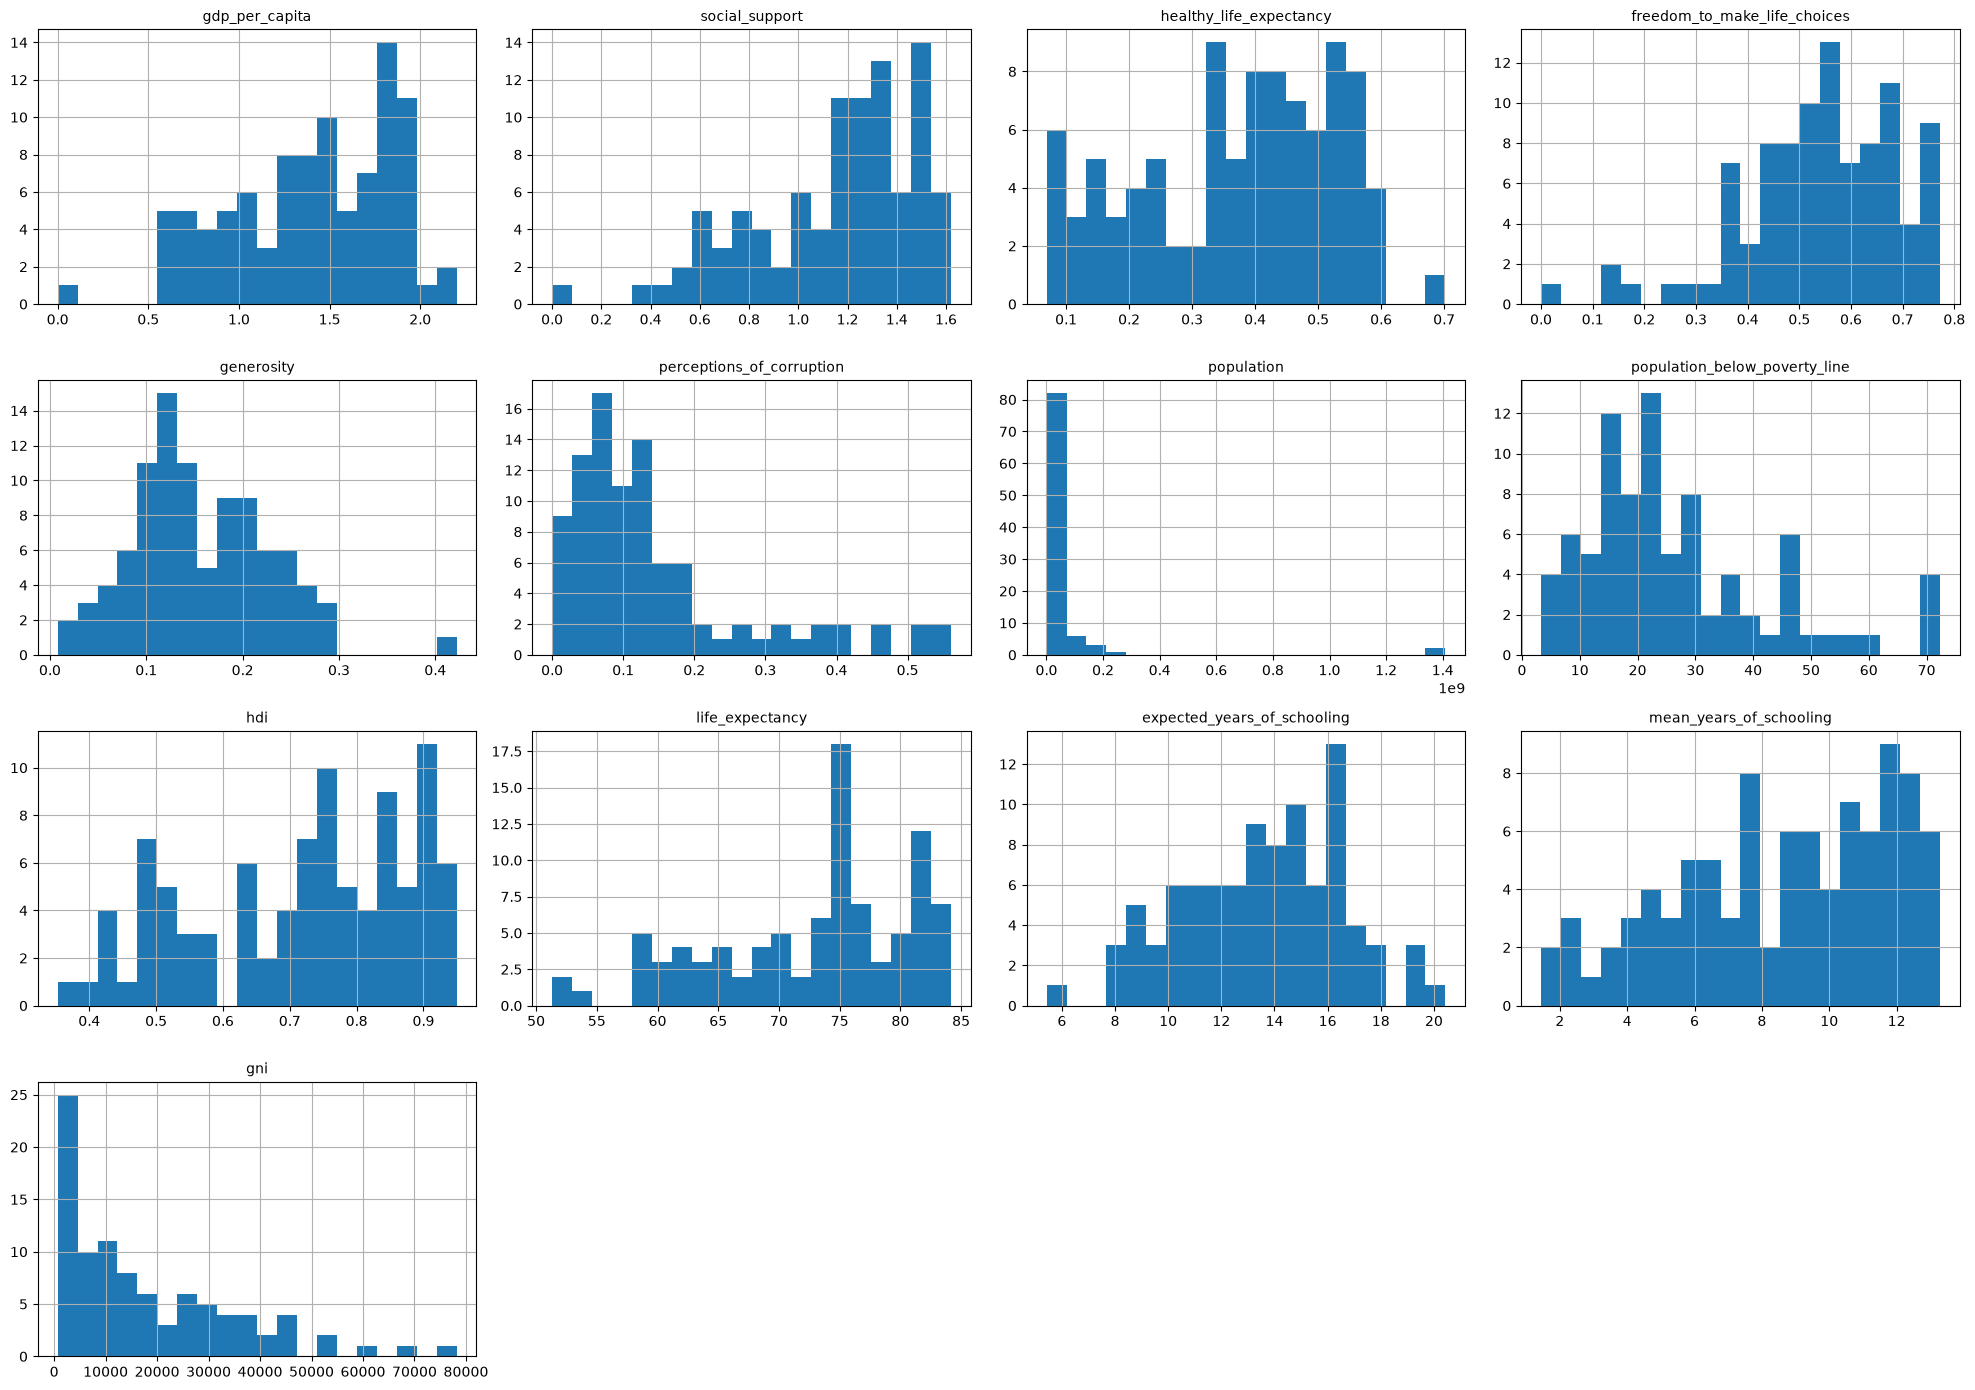

In [10]:
from matplotlib import pyplot as plt
num_col = X_train.select_dtypes(include=['float64']).columns

axes = X_train[num_col].hist(figsize=(20, 14), bins=20, layout=(4, 4))

for ax in axes.flatten():
    ax.title.set_fontsize(10)

plt.subplots_adjust(hspace=0.6, wspace=0.35)
plt.tight_layout()
plt.show()

The most obvious skewness is that `population` and `gni` are extremely right-skewed, which means most of their values cluster on the left. Therefore, it should be transformed and standardized to get a more symmetrical distribution. Besides, `perceptions_of_corruption` and `population_below_poverty_line` are also right-skewed, and `freedom_to_make_life_choices`, `hdi`,.etc look a bit left-skewed. It is probably because there are only 95 observations, and histograms can look noisier than they truly are.  

One notable abnormal value is that a country's GDP per capita is 0. In reality, a country's GDP cannot be 0. Maybe it's a missing/unconfirmed data, and 0 is the placeholder.


### Distribution of Categorical Variables

Plot the distribution of relevant categorical variables using appropriate visualizations (e.g., count plots or bar charts). Briefly comment on class imbalance or notable patterns.

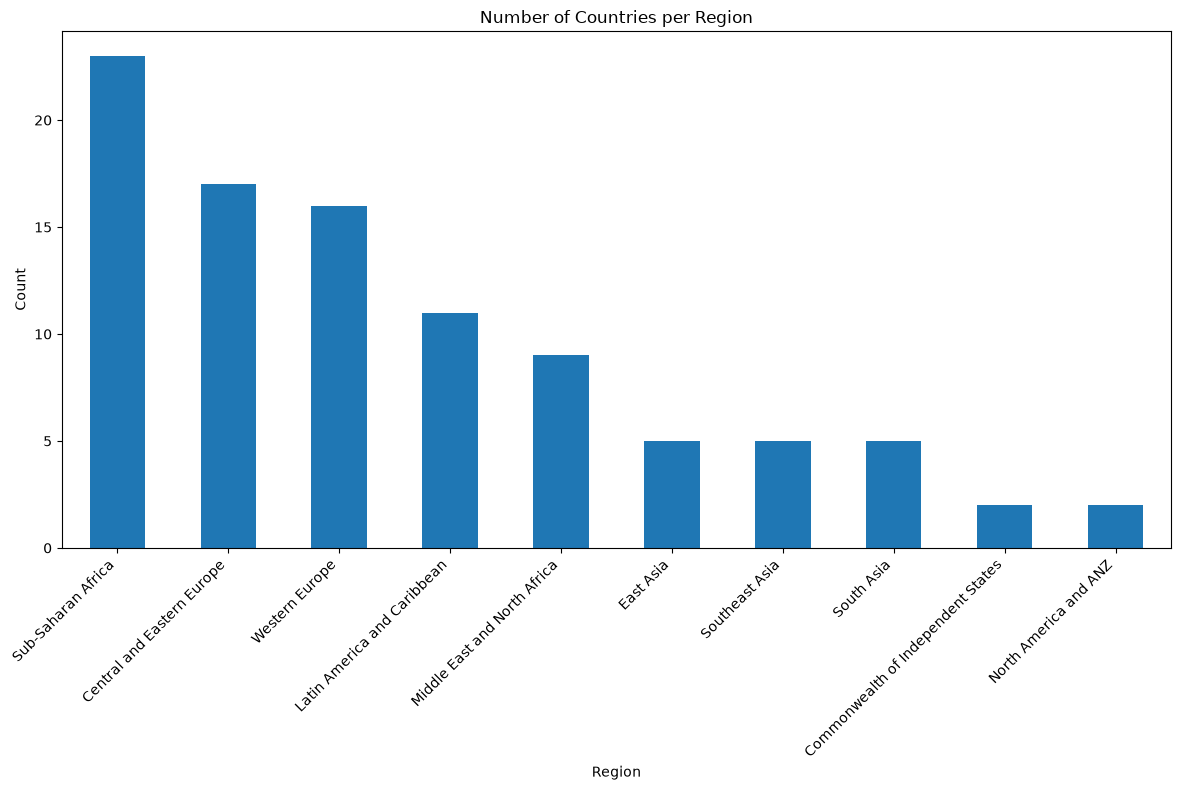

In [11]:
X_train['region'].value_counts().plot(kind='bar', figsize=(12, 8))
plt.title('Number of Countries per Region')
plt.xlabel('Region')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

There is clear imbalance in this bar chart: `Sub-Saharan Africa` includes over 20 countries in this training dataset, while `Commonwealth of Independent States` and `North America and ANZ` categories only have less than 5 countries each. It's a significant disparity in the number.

### Feature Correlation Analysis

Analyze the relationships between numerical features using correlation coefficients. Compute and visualize:

- **Pearson correlation** — linear relationships
- **Spearman correlation** — monotonic relationships
- **Kendall correlation** — rank-based relationships

Use correlation matrices and heatmaps where appropriate. Briefly interpret strong positive or negative correlations and discuss potential multicollinearity.

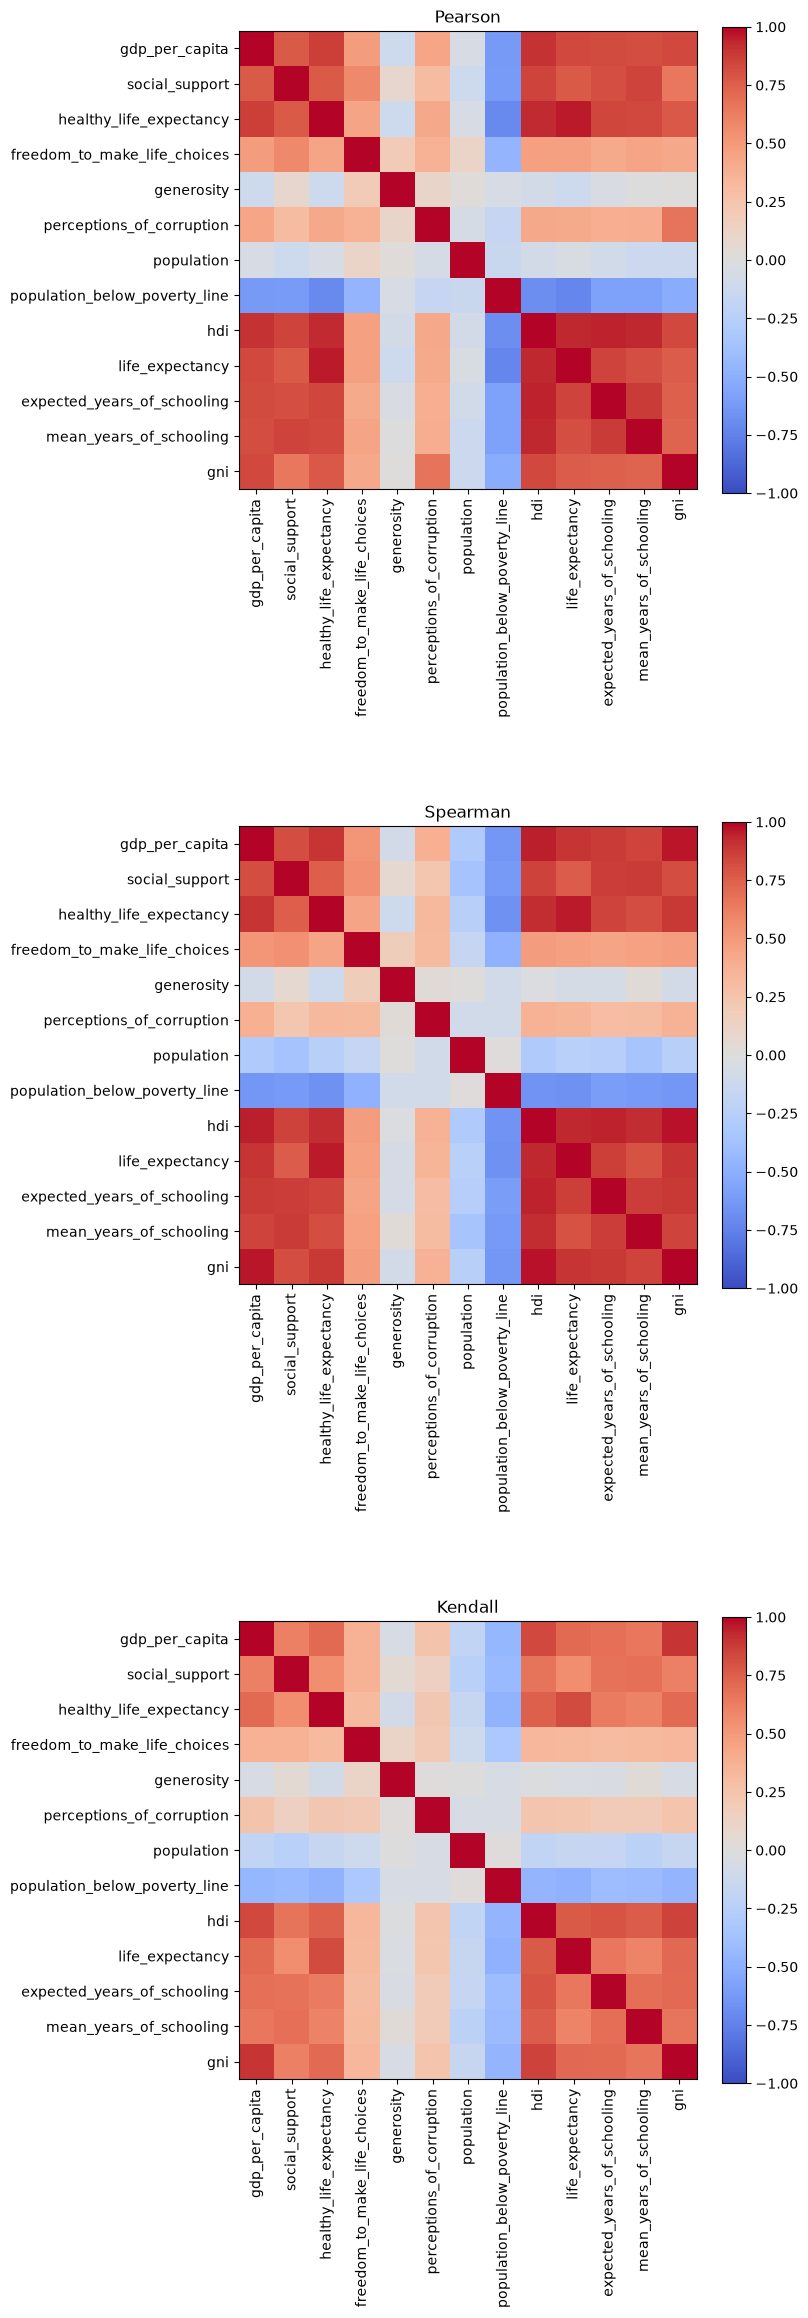

In [12]:
pearson_corr = X_train[num_col].corr(method='pearson')
spearman_corr = X_train[num_col].corr(method='spearman')
kendall_corr = X_train[num_col].corr(method='kendall')

fig, axes = plt.subplots(3, 1, figsize=(8, 24))
for ax, corr, title in zip(axes, [pearson_corr, spearman_corr, kendall_corr], ['Pearson', 'Spearman', 'Kendall']):
    im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.columns)))
    ax.set_yticklabels(corr.columns)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

There are a lot of strong correlations among these numeric variables. For instance, `gdp_per_capita` and `gni`, `hdi` and `gni`, `expected_years_of_schooling` and `hdi` have strong positive correlations (~0.75+) across three correlation models. `life_expectancy` and `population_below_poverty_line` shows an obvious negative correlation, given that countries having more people in poverty issues may have less access to health resources and thus live shorter lives.    

Since `hdi` is calculated and built from some features contributing to human development, including `gdp_per_capita`, `life_expectancy`, `expected_years_of_schooling`.etc, multicollinearity do exist among them. As we will use Randon Forest in the following steps, multicollinearity does not impact predictive capacity for this model much. But we should be aware of its influence on SHAP when interpreting feature importance.

### Bivariate Analysis and Relationship Exploration

Explore relationships between features and examine how they associate with the target variable. Include:

- Bivariate plots (e.g., scatter plots, box plots, grouped bar charts)
- Correlation tables
- Comparisons of feature distributions across target classes

Briefly summarize key relationships and any patterns that may influence model performance.

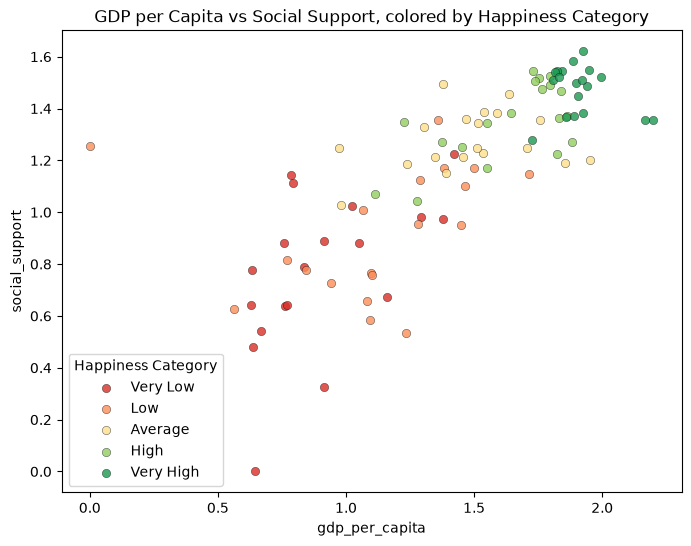

In [13]:
# Scatter plot of GDP per Capita vs Social Support, colored by Happiness Category
category_order = ['Very Low', 'Low', 'Average', 'High', 'Very High']
colors = ['#d73027', '#fc8d59', '#fee08b', '#91cf60', '#1a9850']

plot_df = X_train.copy()
plot_df['happiness_category'] = pd.Categorical(y_train.values, categories=category_order, ordered=True)

fig, ax = plt.subplots(figsize=(8, 6))
for cat, color in zip(category_order, colors):
    mask = plot_df['happiness_category'] == cat
    ax.scatter(plot_df.loc[mask, 'gdp_per_capita'],
               plot_df.loc[mask, 'social_support'],
               label=cat, color=color, alpha=0.8, edgecolor='k', linewidth=0.3)

ax.set_xlabel('gdp_per_capita')
ax.set_ylabel('social_support')
ax.set_title('GDP per Capita vs Social Support, colored by Happiness Category')
ax.legend(title='Happiness Category')
plt.show()

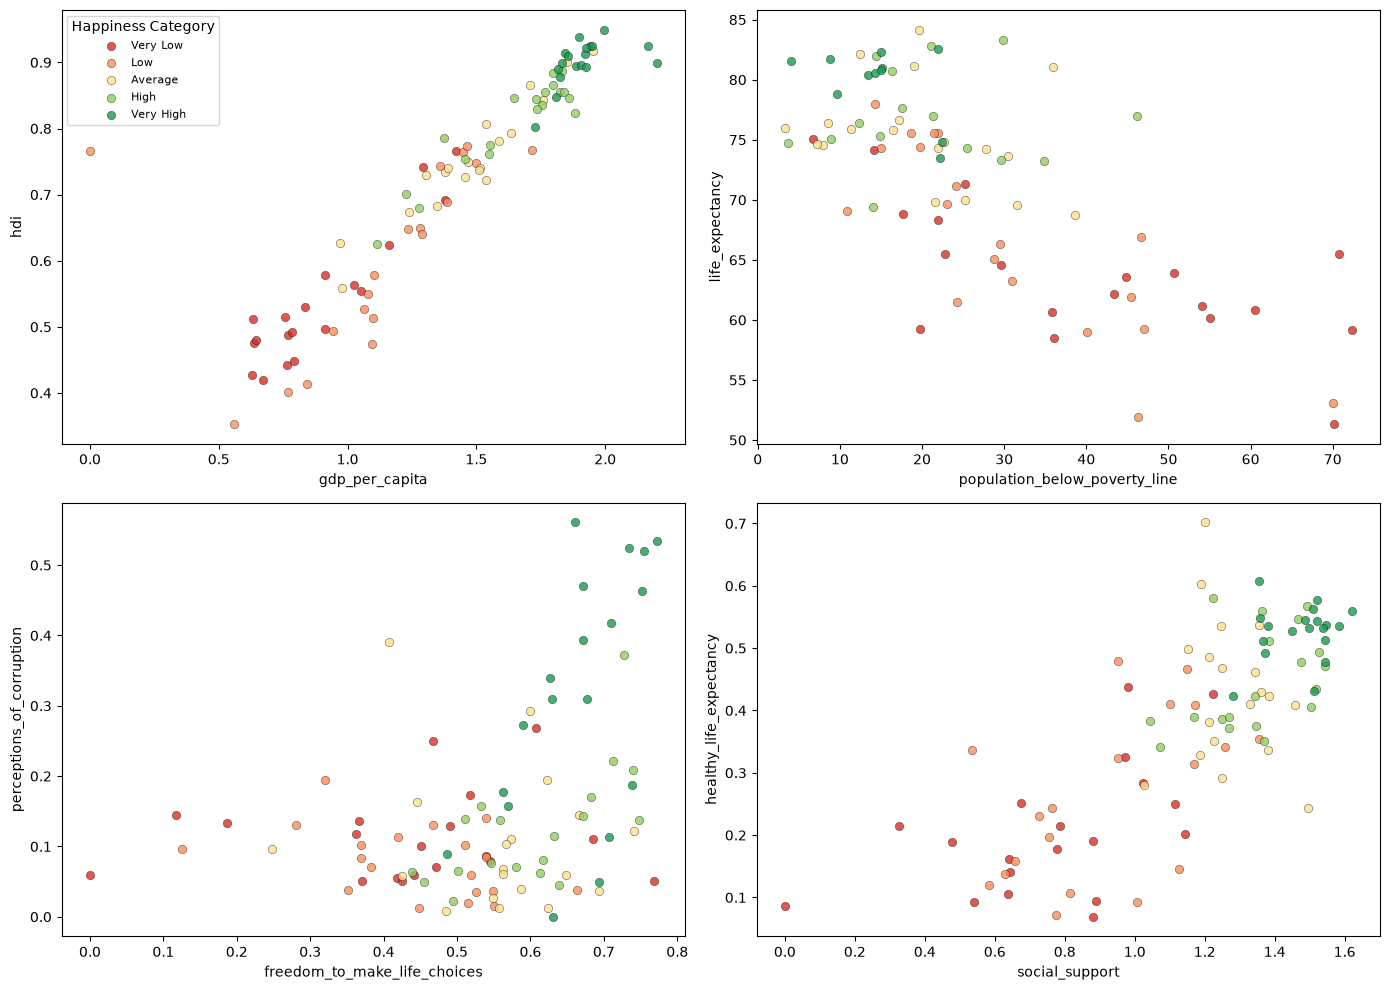

In [14]:
# More scatter plots of paired variables, colored by Happiness Category
pairs = [('gdp_per_capita', 'hdi'),
          ('population_below_poverty_line', 'life_expectancy'),
          ('freedom_to_make_life_choices', 'perceptions_of_corruption'),
          ('social_support', 'healthy_life_expectancy')]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for ax, (xcol, ycol) in zip(axes, pairs):
    for cat, color in zip(category_order, colors):
        mask = plot_df['happiness_category'] == cat
        ax.scatter(plot_df.loc[mask, xcol], plot_df.loc[mask, ycol],
                   label=cat, color=color, alpha=0.8, edgecolor='k', linewidth=0.3)
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
axes[0].legend(title='Happiness Category', fontsize=8)

plt.tight_layout()
plt.show()

In [15]:
# Correlation of features with the target variable
X_train.index = y_train.index
X_test.index = y_test.index

target_corr = pd.DataFrame({
    'pearson': X_train[num_col].corrwith(y_train_labels, method='pearson'),
    'spearman': X_train[num_col].corrwith(y_train_labels, method='spearman')
})
target_corr = target_corr.reindex(target_corr['spearman'].abs().sort_values(ascending=False).index)
target_corr

,pearson,spearman
gdp_per_capita,0.809400,0.841157
social_support,0.787159,0.836026
hdi,0.811641,0.828013
gni,0.768446,0.824569
mean_years_of_schooling,0.758609,0.785350
expected_years_of_schooling,0.756374,0.780972
life_expectancy,0.760111,0.773022
healthy_life_expectancy,0.752381,0.756918
freedom_to_make_life_choices,0.581430,0.613986
population_below_poverty_line,-0.504637,-0.478712


In [16]:
# Comparisons of feature distributions across target classes
category_order = ['Very Low', 'Low', 'Average', 'High', 'Very High']

class_table = X_train[num_col].copy()
class_table['happiness_category'] = pd.Categorical(y_train.values, categories=category_order, ordered=True)

class_summary = class_table.groupby('happiness_category', observed=True)[num_col].mean()
class_summary

,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,population,population_below_poverty_line,hdi,life_expectancy,expected_years_of_schooling,mean_years_of_schooling,gni
happiness_category,,,,,,,,,,,,,
Very Low,0.898474,0.769421,0.205947,0.433105,0.162684,0.112000,9.952305e+07,39.552632,0.539376,63.894947,10.842682,5.673008,3400.339025
Low,1.117368,0.919947,0.260000,0.444526,0.171368,0.079263,5.780789e+07,30.421053,0.604970,66.912789,11.113513,6.233792,7663.733195
Average,1.480421,1.276842,0.430316,0.556000,0.128105,0.105368,9.545578e+07,19.952632,0.754359,75.455158,14.231622,9.115170,15754.221066
High,1.632684,1.349105,0.445158,0.599947,0.147579,0.122947,3.226844e+07,21.287500,0.805969,76.874889,14.922061,10.271467,23301.915609
Very High,1.911316,1.473053,0.525789,0.665053,0.171526,0.310263,1.162380e+07,14.718182,0.901086,80.734333,17.015347,12.163198,41844.896842


From the scatter plots above, we can conclude that countries have higher `gdp_per_capita` and higher `social_support` potentially have higher happiness score. Similarly, countries have higher `gdp_per_capita` and higher `hdi`/ higher `life_expectancy` and lower `population_below_poverty_line`/ higher `social_support` and higher `healthy_life_expectancy` all tend to have higher happiness score as well, though with a few exceptions. However, the interaction between `perceptions_of_corruption` and `freedom_to_make_life_choices` has less obvious impact towards happiness score. This pair does not jointly separate happiness categories well.  

From the correlation table and distribution table, it can be conluded that `gdp_per_capita`, `hdi`, `gni`, and `social_support` show the strongest positive correlations with happiness (ρ≈0.8), along with schooling and life expectancy variables(ρ≈0.75-0.79), which is the same cluster flagged as multicollinear. `freedom_to_make_life_choices` and `perceptions_of_corruption` positively correlated with happiness, while `population_below_poverty_line` and `population` are negatively correlated with it. At last, `generosity` shows essentially no correlation (ρ≈0), showing low importance in modeling.

### Outlier Detection

Identify potential outliers in the numerical features using appropriate methods such as:

- Box plots
- Z-score analysis
- Interquartile Range (IQR) method

Highlight any significant anomalies and briefly comment on whether they should be retained, transformed, or removed.

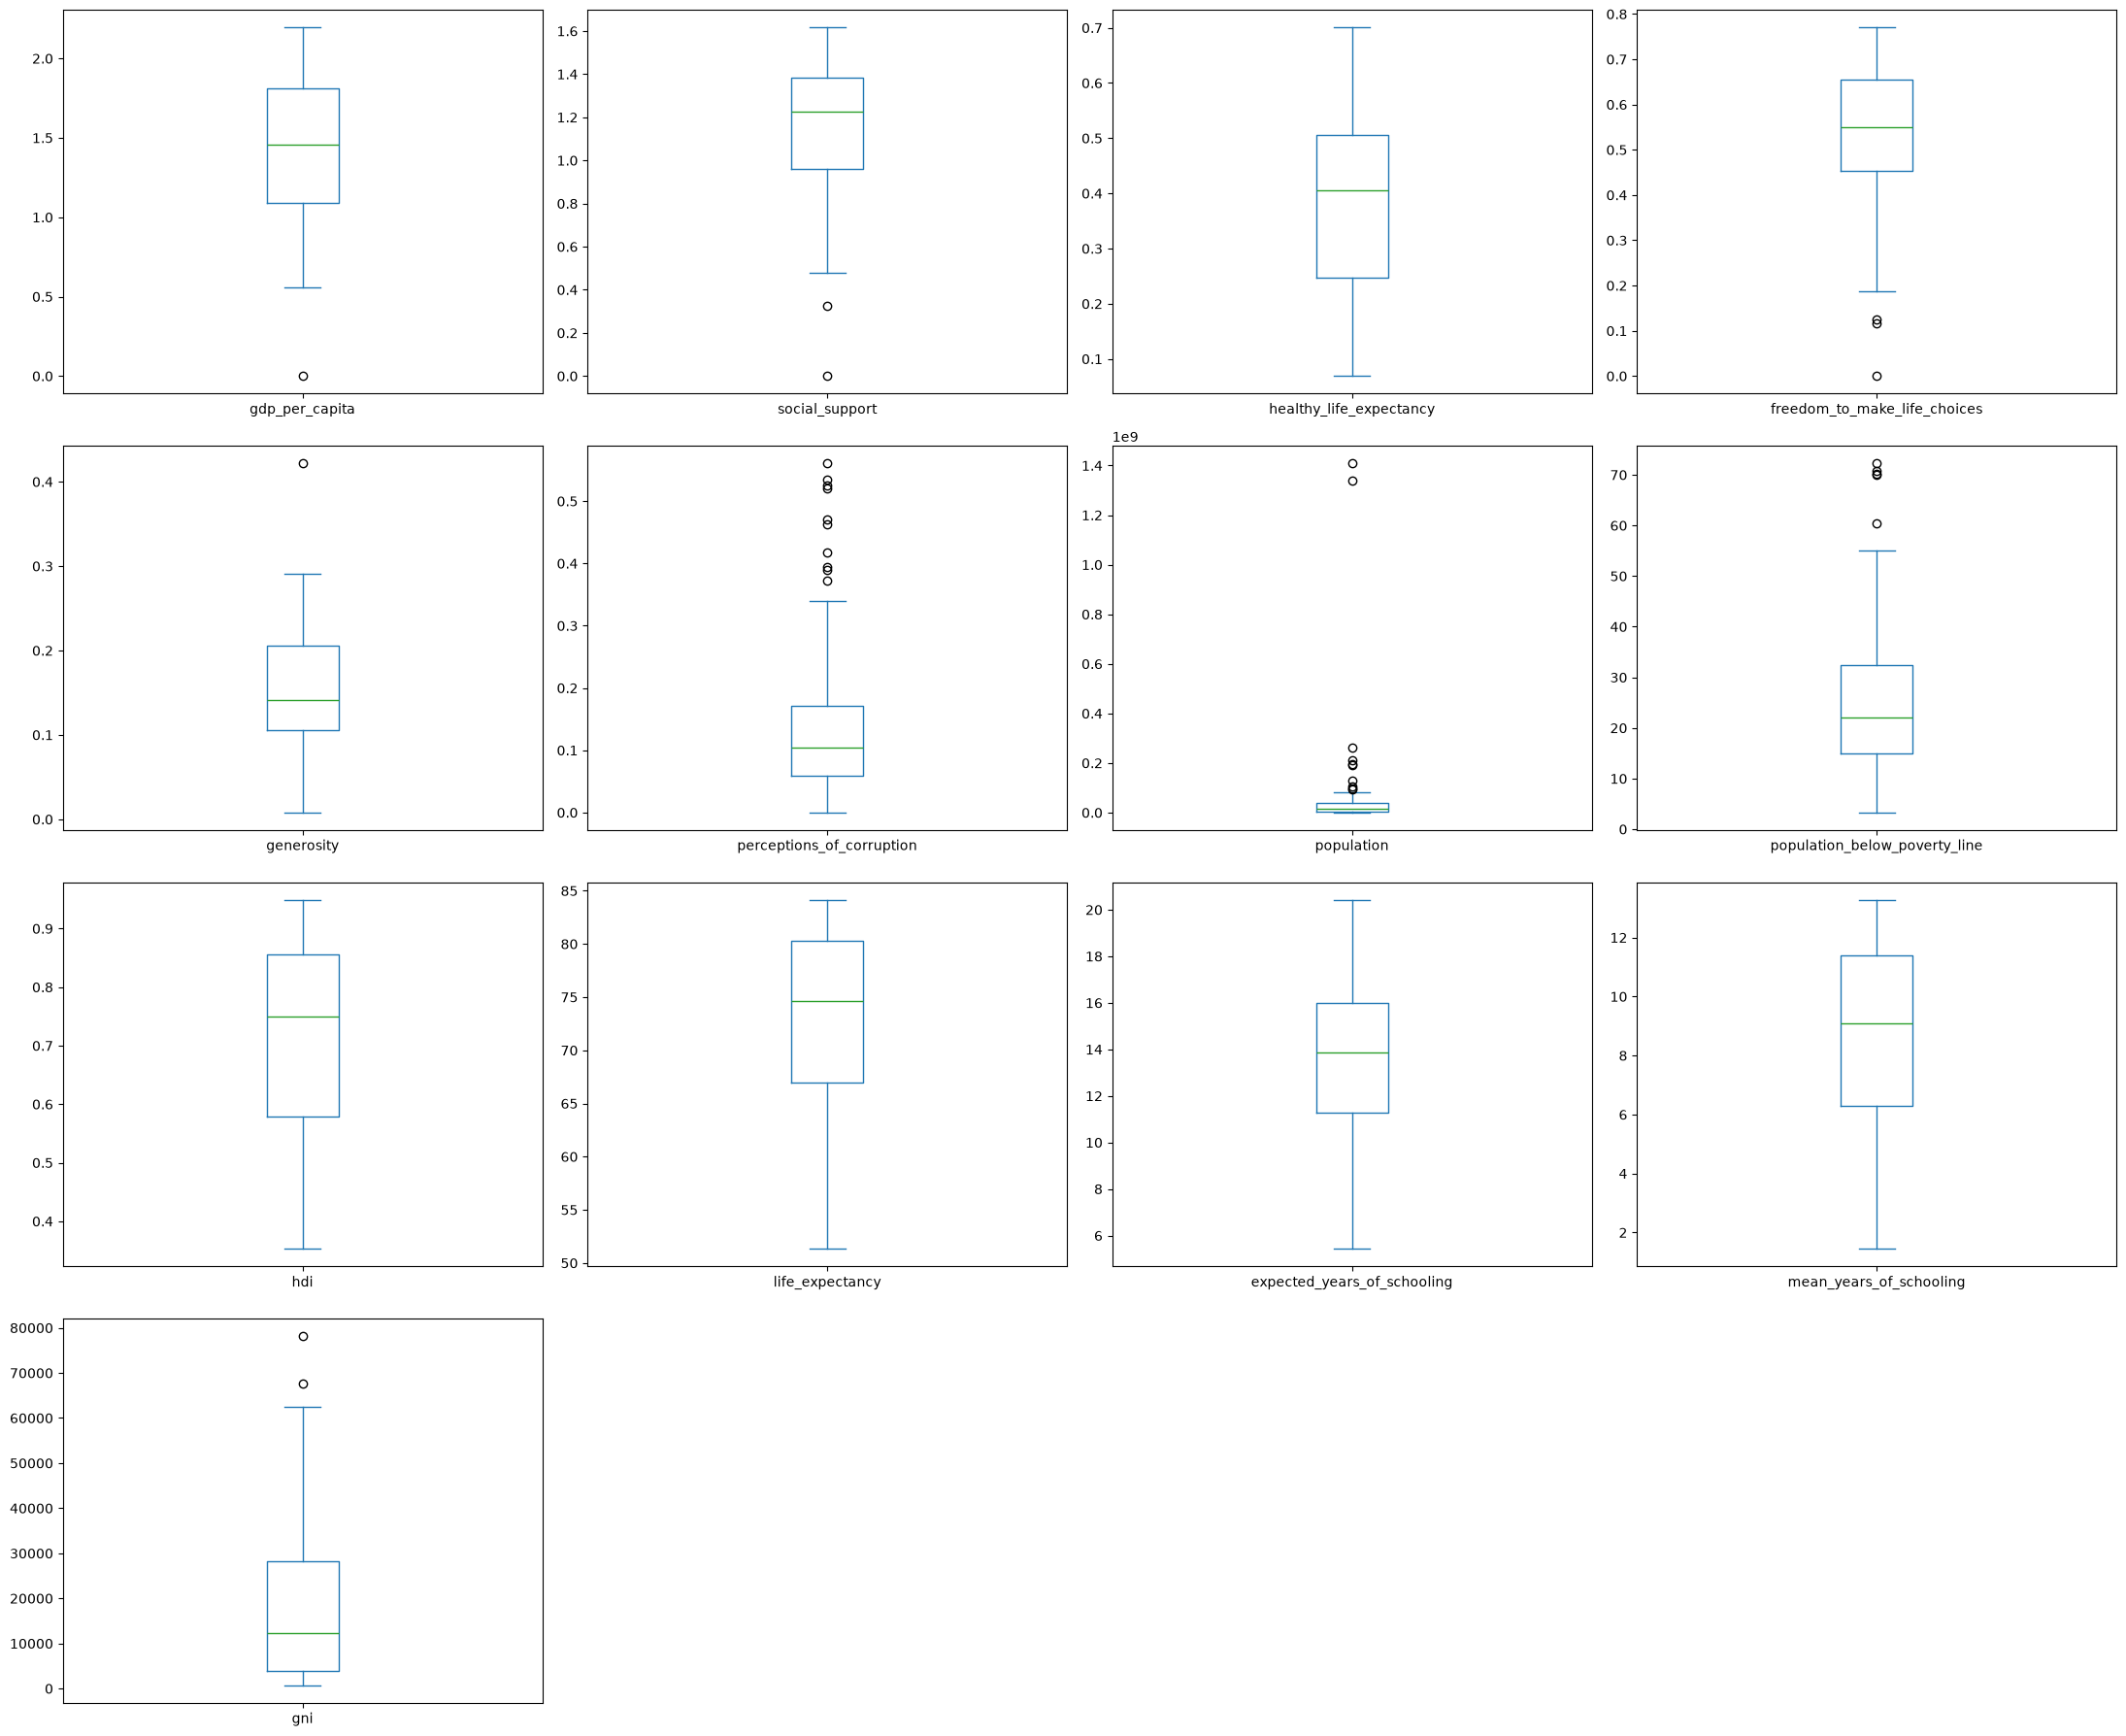

In [17]:
# Boxplots
X_train[num_col].plot(kind='box', subplots=True, layout=(4, 4), figsize=(22, 18), sharex=False, sharey=False)
plt.tight_layout()
plt.show()

Extremely skewed vairables can be corrected by applying log transformations. What should be paid close attention to is the near-zero values of `gdp_per_capita` and `social_support`. It is of little possiblity that a country has 0 gdp per capita or 0 social support across the globe. But we only have 95 observations in the training dataset, it is hasty to directly drop these abnomalies. Removing them will also break the alignment with `y_tain` dataset. Other outliers such as one extremely high generosity index are plausible for some countries.

### Observations and General Comments

Summarize your key findings from the exploratory analysis. Include:

- Important patterns or relationships identified
- Presence of missing values or outliers
- Potential feature engineering considerations
- Any preprocessing steps that should be applied before modeling

Keep your comments concise and evidence-based.

##### Important patterns or relationships identified:
`gdp_per_capita`, `hdi`, `gni`, and `social_support` show the strongest positive correlations with happiness,along with schooling and life expectancy measures. This cluster of variables showed multicollinearity with each other in the correlation heatmap. `population_below_poverty_line` and `population` are negatively correlated with happiness classes. generosity shows essentially no correlation (ρ≈0).

##### Presence of missing values or outliers:
One country failed to match during the merging, producing missing values across all six development-indicator columns for that row. Outlier analysis flagged a near-zero `gdp_per_capita`/`social_support` value as a likely data-quality anomaly, while most other outliers (in i.e. `population`, `gni`, `perceptions_of_corruption`) reflect genuine cross-country variation rather than errors.

##### Potential feature engineering considerations:
`population`, `gni`, `perceptions_of_corruption`, and `population_below_poverty_line` were obviously skewed and should be log-transformed to reduce the influence of extreme values. An interaction feature (gdp_per_capita × social_support) can be added in the model to test their combined interpretability on happiness.

##### Preprocessing steps to apply before modeling:
Impute missing numeric values (i.e. constant fill), impute missing categorical values with the most frequent category, standardize numeric features via StandardScaler given widely varying magnitudes, one-hot encode region, and drop the redundant identifier columns country/country_name. Given generosity's near-zero correlation and the multicollinearity among development indicators, feature importance should be interpreted cautiously in later stages.

---

## 2. Feature Engineering

### Log Transformations

Apply log transformations to normalize skewed numerical features and improve model stability (if applicable).

> **Note:** Apply every feature engineering step to **both** `X_train` and `X_test`, before fitting the preprocessor in Section 3.

In [18]:
import numpy as np
skewed_cols = ['population', 'gni', 'perceptions_of_corruption', 'population_below_poverty_line']

for col in skewed_cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

### Interaction Features

Create at least one interaction feature to capture relationships between existing variables and enhance predictive power.

In [19]:
# Income &/v.s. Social Capital: 
# Scholars have found that rich social capital can weaken the negative effect of income on happiness in a society.
X_train['gdp_social_interaction'] = X_train['gdp_per_capita'] * X_train['social_support']
X_test['gdp_social_interaction'] = X_test['gdp_per_capita'] * X_test['social_support']

---

## 3. Data Preprocessing

Use `sklearn`'s `ColumnTransformer` to preprocess the data. Write a preprocessing function and save the fitted preprocessor for later use.

In [20]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Create the preprocessing pipelines for both numeric and categorical data.
numeric_features = X_train.select_dtypes(include='number')
numeric_features = numeric_features.columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())]) # You will need to describe why this is being done in the next cell

categorical_features = ['region']

# Replacing missing values with Modal value and then one hot encoding.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

# final preprocessor object set up with ColumnTransformer
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

# Fit your preprocessor object
preprocess = preprocessor.fit(X_train)

### Explanation

Briefly explain what the preprocessing steps above do and why they are needed.

If you changed the imputation strategy (or any other preprocessing choice), please state:

- What you changed
- Why you made that change

What these preprocessing steps do are: 1) separating numeric and categorical variables. 2) for numerics ones, imputation comes first, filling all missing values with the median of that column. And then, each column is standardized and rescaled so that all of them have mean 0 and std 1. 3) for the categorical column, the pipeline first fills the missing values with the most frequent value of the corresponding column, and the handle_unknown='ignore' prevents the encoder from crashing if the model sees an unfamiliar category in `X_test`.  

I changed the filling of numeric missing values from a constant value '0' into the median of a set of values. '0' a is relatively unrealistic data for most of the features, for example, `hdi` and `population` can hardly equal to '0'. Also, to many '0's can make `StandardScaler` part become more extreme.

In [21]:
# function to transform data with preprocessor

def preprocessor(data):
    preprocessed_data=preprocess.transform(data)
    return preprocessed_data

In [22]:
preprocessor(X_train)

array([[-1.74797303, -1.14773129, -1.26057982, ...,  0.        ,
         1.        ,  0.        ],
       [-0.696107  , -1.19319516, -0.83488717, ...,  0.        ,
         1.        ,  0.        ],
       [-0.06543785,  1.01937962, -0.83488717, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.22962521,  0.27680315,  0.6098879 , ...,  0.        ,
         0.        ,  0.        ],
       [-0.04066156, -0.01416558,  0.80983445, ...,  0.        ,
         0.        ,  0.        ],
       [-0.2321147 ,  0.5192771 ,  0.24224424, ...,  0.        ,
         0.        ,  0.        ]], shape=(95, 24))

### Conceptual Question

Explain the differences between the following:

- The `preprocessor` **object**
- The `preprocess` **object**
- The `preprocessor` **function**
- The final `preprocessed_data` **returned**

Clearly distinguish between objects, functions, and transformed data.

The `preprocessor` object is `ColumnTransformer`, which is unfitted and describes how different columns are going to be transformed; the `preprocess` object is the fitted `ColumnTransformer`; the `preprocessor` function is a simple fuction to call `preprocess.transform()`, enabling us to see the transformed and fitted(learned) data; the final `preprocessed_data` returned shows the result(an array of numbers) of the function.

In [23]:
# check shape of X data after preprocessing it using our new function
preprocessor(X_train).shape

(95, 24)

---

## 4. Model Training and Saving Artifacts

Fit the model on the preprocessed training data. Save the fitted preprocessor and the trained model for reuse (e.g., to make predictions later without retraining).

In [24]:
from sklearn.ensemble import RandomForestClassifier
import joblib

model = RandomForestClassifier(random_state=42)
model.fit(preprocessor(X_train), y_train)

# Your cell should have a score between 0-1 as output
train_score = model.score(preprocessor(X_train), y_train)
print(f"Training accuracy: {train_score:.3f}")

# Save the fitted preprocessor and the trained model for reuse (e.g., using joblib)
joblib.dump(preprocess, 'fitted_preprocessor.joblib')
joblib.dump(model, 'random_forest_model.joblib')

Training accuracy: 1.000


['random_forest_model.joblib']

---

## 5. Model Evaluation

Generate predictions using `X_test`. Compare the predictions with the true labels in `y_test` using appropriate evaluation metrics.

Test accuracy: 0.595

              precision    recall  f1-score   support

     Average       0.58      0.88      0.70         8
        High       0.62      0.62      0.62         8
         Low       0.38      0.38      0.38         8
   Very High       0.86      0.67      0.75         9
    Very Low       0.57      0.44      0.50         9

    accuracy                           0.60        42
   macro avg       0.60      0.60      0.59        42
weighted avg       0.61      0.60      0.59        42



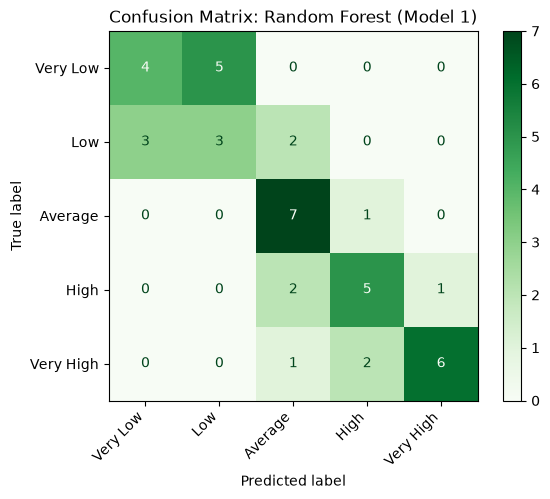

In [25]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Generate predicted values (Model 1)
prediction_labels = model.predict(preprocessor(X_test))

# Write lines of code to show model performance by comparing prediction_labels with true labels
print(f"Test accuracy: {accuracy_score(y_test, prediction_labels):.3f}")
print()
print(classification_report(y_test, prediction_labels))

cm = confusion_matrix(y_test, prediction_labels, labels=category_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=category_order)
disp.plot(cmap='Greens')
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix: Random Forest (Model 1)')
plt.show()

Training accuracy = 1.000 v.s. Test accuracy = 0.595 indicates this model has overfitting problem.

---

## 6. Hyperparameter Experimentation

Repeat the training and evaluation process with different model parameters to improve performance. Track results across experiments and report the best-performing configuration.

In [26]:
# Train model 2 using same preprocessor (note that you could save a new preprocessor, but we will use the same one for this example).
from sklearn.ensemble import RandomForestClassifier

model_2 = RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
)
model_2.fit(preprocessor(X_train), y_train)

train_score_2 = model_2.score(preprocessor(X_train), y_train)
print(f"Training accuracy: {train_score_2:.3f}")

Training accuracy: 0.947


### Reflection on Hyperparameter Changes

Briefly explain:

- What parameters you changed
- What each parameter controls
- Why the changes improved (or did not improve) performance

Support your explanation with evidence from your results.

I changed `n_estimators`(100->200), `max_depth`(100->6) and `min_samples_leaf`(1->2). `n_estimators` controls the number of trees averaged, `max_depth` controls how many splits deep each tree can go, and `min_samples_leaf` sets the minimum samples required in each leaf. Compared with Model 1, Model 2 reduces the training accauracy, making the model less overfitting. It is not completely memorizing everthing in the training dataset now. But the test accuracy score is also reduced, meaning that Model 2 may take away some useful patterns and flexibility.

Test accuracy: 0.524

              precision    recall  f1-score   support

     Average       0.55      0.75      0.63         8
        High       0.57      0.50      0.53         8
         Low       0.30      0.38      0.33         8
   Very High       0.86      0.67      0.75         9
    Very Low       0.43      0.33      0.38         9

    accuracy                           0.52        42
   macro avg       0.54      0.53      0.52        42
weighted avg       0.55      0.52      0.53        42



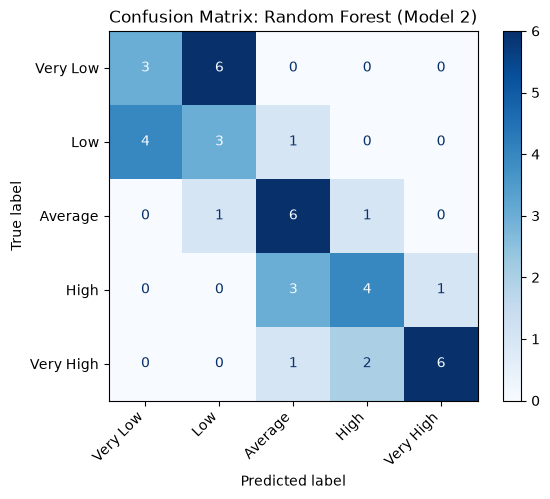

In [27]:
# Evaluate Model 2:

# Generate predicted y values (Model 2)
prediction_labels_2 = model_2.predict(preprocessor(X_test))
print(f"Test accuracy: {accuracy_score(y_test, prediction_labels_2):.3f}")
print()
print(classification_report(y_test, prediction_labels_2))

# Write lines of code below to show model performance by comparing prediction_labels with true labels
cm = confusion_matrix(y_test, prediction_labels_2, labels=category_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=category_order)
disp.plot(cmap='Blues')
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix: Random Forest (Model 2)')
plt.show()

### Discussion Question

Do you think it is worth making more changes to the parameters? Should we keep trying random values and see what works better? What is an alternative to doing this manually?

Yes, I think it is worth making more changes to get better accuracy scores. But manually revising the parameters is not a wise choice since it has diminishing results and limitations in exploring full ranges of the parameters.

### Grid Search (Model 3)

Use `GridSearchCV` to search systematically over Random Forest hyperparameters.

In [28]:
# Train a third model using GridSearchCV

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import numpy as np

param_grid = {'n_estimators': np.arange(100, 501, 100), 
              'max_depth': np.arange(3, 11, 1),
              'min_samples_leaf': np.arange(1, 5, 1)
}

# Create a RandomForestClassifier object
rf = RandomForestClassifier(random_state=42)
grid = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy')

#Fit the GridSearchCV object to the preprocessed training data
grid.fit(preprocessor(X_train), y_train)


#extract best score and parameter by calling objects "best_score_" and "best_params_"
print("best mean cross-validation score: {:.3f}".format(grid.best_score_))
print("best parameters: {}".format(grid.best_params_))

# Make predictions using the best model
prediction_labels_3 = grid.predict(preprocessor(X_test))


best mean cross-validation score: 0.589
best parameters: {'max_depth': np.int64(4), 'min_samples_leaf': np.int64(1), 'n_estimators': np.int64(300)}


Test accuracy: 0.524

              precision    recall  f1-score   support

     Average       0.50      0.75      0.60         8
        High       0.57      0.50      0.53         8
         Low       0.25      0.25      0.25         8
   Very High       0.86      0.67      0.75         9
    Very Low       0.50      0.44      0.47         9

    accuracy                           0.52        42
   macro avg       0.54      0.52      0.52        42
weighted avg       0.54      0.52      0.53        42



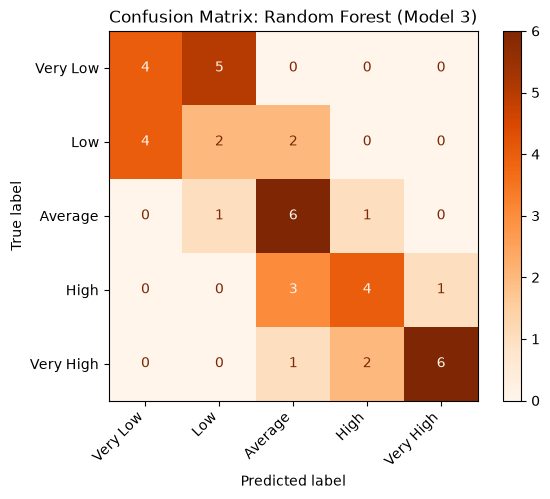

In [29]:
# Evaluate Model 3:

# Generate predicted values
prediction_labels_3 = grid.predict(preprocessor(X_test))
print(f"Test accuracy: {accuracy_score(y_test, prediction_labels_3):.3f}")
print()
print(classification_report(y_test, prediction_labels_3))

# Write lines of code to show model performance by comparing prediction_labels with true labels
cm = confusion_matrix(y_test, prediction_labels_3, labels=category_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=category_order)
disp.plot(cmap='Oranges')
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix: Random Forest (Model 3)')
plt.show()

### Other Classical Models

Train at least one other model from the list below and compare it with your Random Forest models.

Test accuracy: 0.524

              precision    recall  f1-score   support

     Average       0.38      0.62      0.48         8
        High       0.50      0.50      0.50         8
         Low       0.43      0.38      0.40         8
   Very High       1.00      0.56      0.71         9
    Very Low       0.56      0.56      0.56         9

    accuracy                           0.52        42
   macro avg       0.57      0.52      0.53        42
weighted avg       0.58      0.52      0.53        42



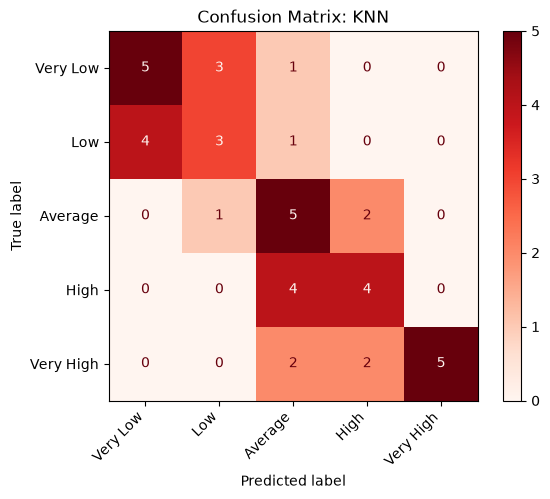

In [30]:
# Here are several classic ML architectures you can consider choosing from to experiment with next:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier


model_knn = KNeighborsClassifier(n_neighbors=5)
model_knn.fit(preprocessor(X_train), y_train)

# Generate predicted values
prediction_labels_knn = model_knn.predict(preprocessor(X_test))
print(f"Test accuracy: {accuracy_score(y_test, prediction_labels_knn):.3f}")
print()
print(classification_report(y_test, prediction_labels_knn))

# Write lines of code to show model performance by comparing prediction_labels with true labels
cm = confusion_matrix(y_test, prediction_labels_knn, labels=category_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=category_order)
disp.plot(cmap='Reds')
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix: KNN')
plt.show()

### Discussion Question

Describe the parameters you defined in `GradientBoostingClassifier`, and/or `BaggingClassifier`, and/or `KNN`, and/or `SVC`. What worked and why?

In KNN, I set `n_neighbors=5` and used default parameters in scikit-learn package, because the sample is really small had has 5 categories. There should be a balance between learning more from the noisy individuals and avoid over-fitting. It reaches a test accuracy score of 0.524, a similar level compared to Random Forest Models, but lower than the best RF test accuracy(~0.59).

---

## 7. Basic Deep Learning

In [31]:
# Now experiment with deep learning models:
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation

# Preprocess input features
X_train_processed = preprocessor(X_train)
X_test_processed = preprocessor(X_test)

feature_count = X_train_processed.shape[1]

# Encode categorical labels as one-hot and store them in y_train_oh (e.g., with pd.get_dummies)
y_train_oh = pd.get_dummies(y_train)

# Define a Neural Network Model with 5 layers 128->64->64->32->(?)
keras_model = Sequential([
    Dense(128, activation='relu', input_shape=(feature_count,)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(y_train_oh.shape[1], activation='softmax')
]) 
# Use Softmax activation in last layer. How many neurons should there be in the last layer?
# 5 neurons should be in the last layer, corresponding to the 5 happiness categories.

# Compile model
keras_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Fitting the NN to the Training set
history = keras_model.fit(preprocessor(X_train), y_train_oh, # Note that keras models require a one-hot-encoded y_train object
               batch_size = 20,
               epochs = 300, validation_split=0.25)

Epoch 1/300


/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.2254 - loss: 1.6131 - val_accuracy: 0.0833 - val_loss: 1.5975
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2676 - loss: 1.5938 - val_accuracy: 0.2083 - val_loss: 1.5936
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2817 - loss: 1.5772 - val_accuracy: 0.2083 - val_loss: 1.5899
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2676 - loss: 1.5602 - val_accuracy: 0.2083 - val_loss: 1.5872
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3521 - loss: 1.5434 - val_accuracy: 0.2083 - val_loss: 1.5843
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3521 - loss: 1.5290 - val_accuracy: 0.2083 - val_loss: 1.5815
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3521 - loss: 1.5148 - val_accuracy: 0.2083 - val_loss: 1.5786
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3944 - loss: 1.5025 - val_accuracy: 0.2083 - val_loss: 1.5757
Epoch 9/300

### Discussion Question

Which activation functions did you use in the hidden layers? Why was **softmax** used in the final layer?

`ReLU` was used in the hidden layers because `ReLU` enables early layers can also learn effectively.  

`Softmax` was used in the output layer. It converts raw outputs into a proper probability distribution across the 5 classes, which is required for multi-class classification and `categorical_crossentropy` loss.

### Discussion Question

Was it a good idea to train for 300 epochs? Should you train longer? Why or why not?

No, it was not a good idea. We should not train longer, since it has already been overfitting. Validation loss increased and validation accuracy reduced before 300 epochs.

### Discussion Question

Why was `loss='categorical_crossentropy'` and `optimizer='sgd'` used? Would you change anything? Why or why not?

`Categorical_crossentropy` is the standard loss for multi-class classification with one-hot targets, which is a good match to our `softmax` output. `Sgd` is the simplest optimizer with fixed learning rate, and no momentum or adaptive adjustment. Maybe I would consider switching to `adam`. Because it converges faster and more reliably, especially useful for small, noisy dataset.

### Plot Training Curves

Extract the model training history and plot the learning curves (e.g., training vs. validation loss and accuracy) across epochs.

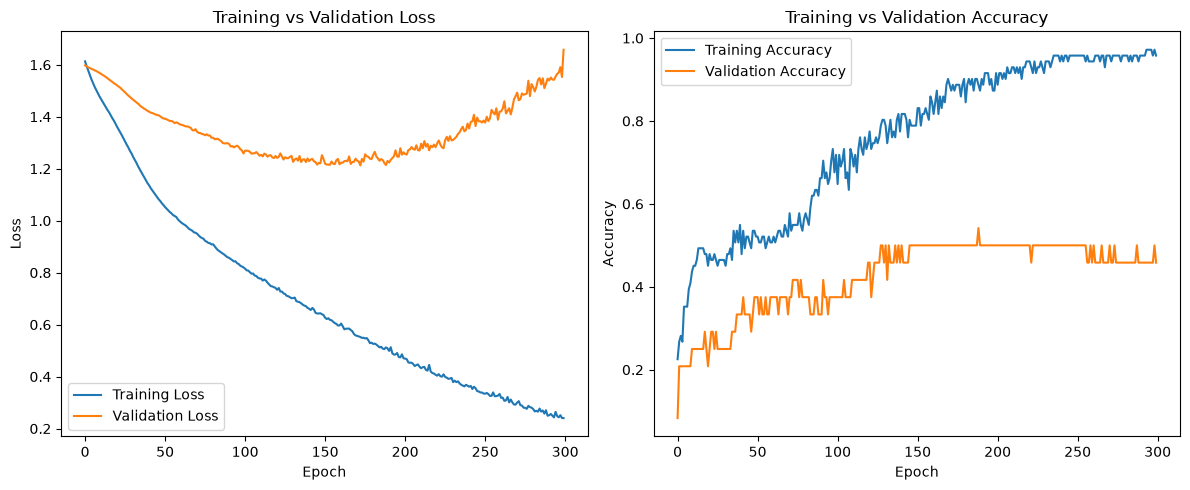

In [32]:
# Your code to plot training and validation curves in a single plot (Make changes in the model cell to be able to do this)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

### Evaluate the Neural Network on the Test Set

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Test accuracy: 0.595

              precision    recall  f1-score   support

     Average       0.67      0.75      0.71         8
        High       0.57      0.50      0.53         8
         Low       0.40      0.50      0.44         8
   Very High       0.78      0.78      0.78         9
    Very Low       0.57      0.44      0.50         9

    accuracy                           0.60        42
   macro avg       0.60      0.59      0.59        42
weighted avg       0.60      0.60      0.59        42



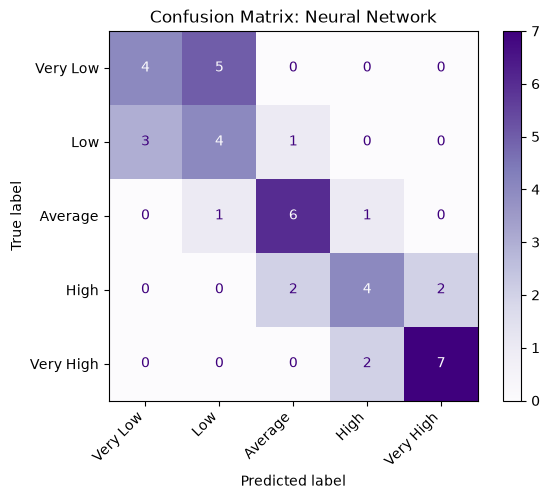

In [33]:
#-- Generate predicted y values

#Note: Keras predict returns class probabilities (one column per class).
#Use np.argmax(..., axis=1) to get the predicted column index for each row.
prediction_column_index = np.argmax(keras_model.predict(preprocessor(X_test)), axis=1)

# extract correct prediction labels
prediction_labels_neu = [y_train_oh.columns[i] for i in prediction_column_index]

# Write lines of code to show model performance by comparing prediction_labels with true labels
print(f"Test accuracy: {accuracy_score(y_test, prediction_labels_neu):.3f}")
print()
print(classification_report(y_test, prediction_labels_neu))

cm = confusion_matrix(y_test, prediction_labels_neu, labels=category_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=category_order)
disp.plot(cmap='Purples')
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix: Neural Network')
plt.show()

### Regularization: Dropout and Batch Normalization

Implement regularization techniques such as **Dropout** and **Batch Normalization** to improve generalization and observe the change in performance.

> **Note:** Compare training vs. test (or validation) loss and accuracy before and after adding regularization.

Epoch 1/300


/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.2254 - loss: 2.0989 - val_accuracy: 0.2917 - val_loss: 1.5821
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2676 - loss: 2.0172 - val_accuracy: 0.2500 - val_loss: 1.5763
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2676 - loss: 1.7608 - val_accuracy: 0.2917 - val_loss: 1.5626
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3099 - loss: 1.9246 - val_accuracy: 0.2083 - val_loss: 1.5519
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2817 - loss: 1.7581 - val_accuracy: 0.3750 - val_loss: 1.5421
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3521 - loss: 1.6434 - val_accuracy: 0.3750 - val_loss: 1.5366
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3662 - loss: 1.6309 - val_accuracy: 0.4167 - val_loss: 1.5360
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.3239 - loss: 1.6562 - val_accuracy: 0.4167 - val_loss: 1.5317
Epoch 9/300

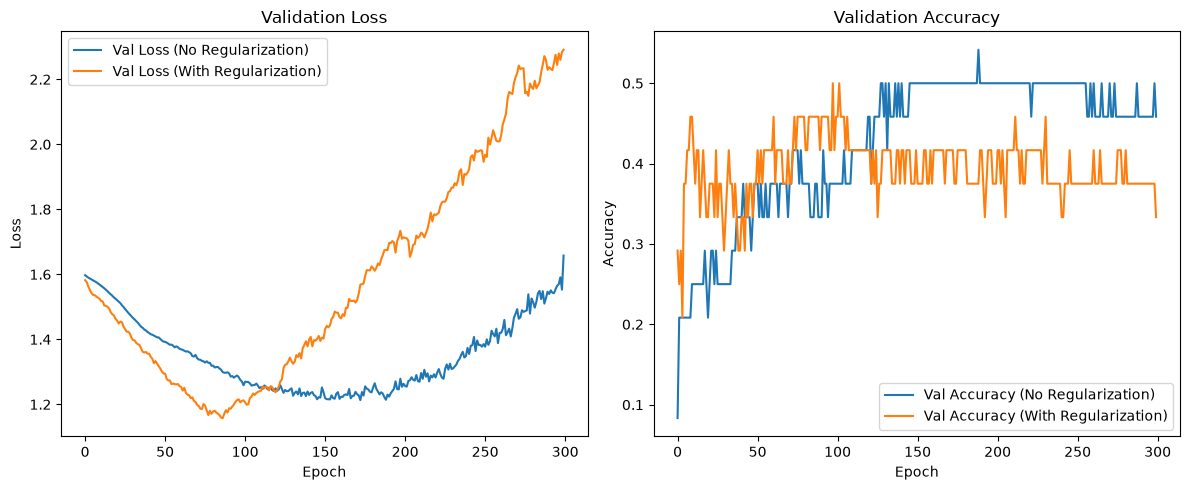

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Test accuracy (Regularized): 0.571
              precision    recall  f1-score   support

     Average       0.50      0.62      0.56         8
        High       0.44      0.50      0.47         8
         Low       0.55      0.75      0.63         8
   Very High       0.83      0.56      0.67         9
    Very Low       0.67      0.44      0.53         9

    accuracy                           0.57        42
   macro avg       0.60      0.57      0.57        42
weighted avg       0.61      0.57      0.57        42



In [34]:
# Write your lines of code here
from keras.layers import Dropout, BatchNormalization

keras_model_reg = Sequential([
    Dense(128, activation='relu', input_shape=(feature_count,)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(y_train_oh.shape[1], activation='softmax')
])

keras_model_reg.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

history_reg = keras_model_reg.fit(preprocessor(X_train), y_train_oh,
               batch_size=20, epochs=300, validation_split=0.25)

# Compare before vs after
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['val_loss'], label='Val Loss (No Regularization)')
plt.plot(history_reg.history['val_loss'], label='Val Loss (With Regularization)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Validation Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy (No Regularization)')
plt.plot(history_reg.history['val_accuracy'], label='Val Accuracy (With Regularization)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Validation Accuracy'); plt.legend()
plt.tight_layout()
plt.show()

# Test set comparison
pred_idx_reg = np.argmax(keras_model_reg.predict(preprocessor(X_test)), axis=1)
pred_labels_reg = [y_train_oh.columns[i] for i in pred_idx_reg]
print(f"Test accuracy (Regularized): {accuracy_score(y_test, pred_labels_reg):.3f}")
print(classification_report(y_test, pred_labels_reg))

Regularization **decreased** test accuracy(0.595->0.571). With only ~71 training rows, the unregularized network probably isn't overfitting much to begin with, so the 30% dropout removed useful model capacity rather than fixing overfitting, pushing it toward underfitting instead. A lighter dropout rate might work better on this small dataset.

### Activation Function Experimentation

Experiment with different activation functions — **ReLU**, **LeakyReLU**, **Tanh**, and **Sigmoid** — and compare their impact on model performance.

In [35]:
# Your lines of code here
from keras.layers import LeakyReLU

results = {}

for act in ['relu', 'tanh', 'sigmoid']:
    m = Sequential([
        Dense(128, activation=act, input_shape=(feature_count,)),
        Dense(64, activation=act),
        Dense(64, activation=act),
        Dense(32, activation=act),
        Dense(y_train_oh.shape[1], activation='softmax')
    ])
    m.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
    m.fit(preprocessor(X_train), y_train_oh, batch_size=20, epochs=300, validation_split=0.25, verbose=0)
    pred_idx = np.argmax(m.predict(preprocessor(X_test)), axis=1)
    pred_labels = [y_train_oh.columns[i] for i in pred_idx]
    results[act] = accuracy_score(y_test, pred_labels)

# LeakyReLU needs its own layer (it takes a slope parameter)
m_leaky = Sequential([
    Dense(128, input_shape=(feature_count,)), LeakyReLU(alpha=0.1),
    Dense(64), LeakyReLU(alpha=0.1),
    Dense(64), LeakyReLU(alpha=0.1),
    Dense(32), LeakyReLU(alpha=0.1),
    Dense(y_train_oh.shape[1], activation='softmax')
])
m_leaky.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
m_leaky.fit(preprocessor(X_train), y_train_oh, batch_size=20, epochs=300, validation_split=0.25, verbose=0)
pred_idx = np.argmax(m_leaky.predict(preprocessor(X_test)), axis=1)
pred_labels = [y_train_oh.columns[i] for i in pred_idx]
results['leaky_relu'] = accuracy_score(y_test, pred_labels)

print(results)

/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/stepWARNING:tensorflow:6 out of the last 6 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x12537eac0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
{'relu': 0.6190476190476191, 'tanh': 0.5238095238095238, 'sigmoid': 0.21428571428571427, 'leaky_relu': 0.5952380952380952}


|Activation |Test Accuracy|
|-----------|-------------|
|   relu	|    0.643    |
|leaky_relu |    0.619    |
|   tanh    |    0.524    |
|  sigmoid	|    0.214    |   

`ReLU` performed best among four activation functions, followed by `LeakyReLU`. `Tanh` and especially `Sigmoid` perform barely above random chance, thus they are much worse choices. This is consistent with the vanishing gradient problem: sigmoid's gradients shrink toward '0' for inputs far from '0', and across this 5-layer network those small gradients get multiplied together during backpropagation, leaving early layers unable to learn effectively. By constrast, `ReLU` avoids this since its gradient stays constant ('0' or '1') for positive inputs. That is why `ReLU` is the standard default for hidden layers in neural network models.

---

## 8. Explainability – SHAP Feature Importance

To better understand the model's predictions, we will use **SHAP (SHapley Additive exPlanations)** to analyze feature importance.

**How SHAP works:**

- SHAP assigns each feature a contribution score for every prediction.
- It uses Shapley values (from cooperative game theory) to fairly distribute importance across features.

We will apply SHAP to visualize and interpret the model's feature contributions.

/Users/navilier/Desktop/Fall2026_QMSS5074GR_Project_1/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


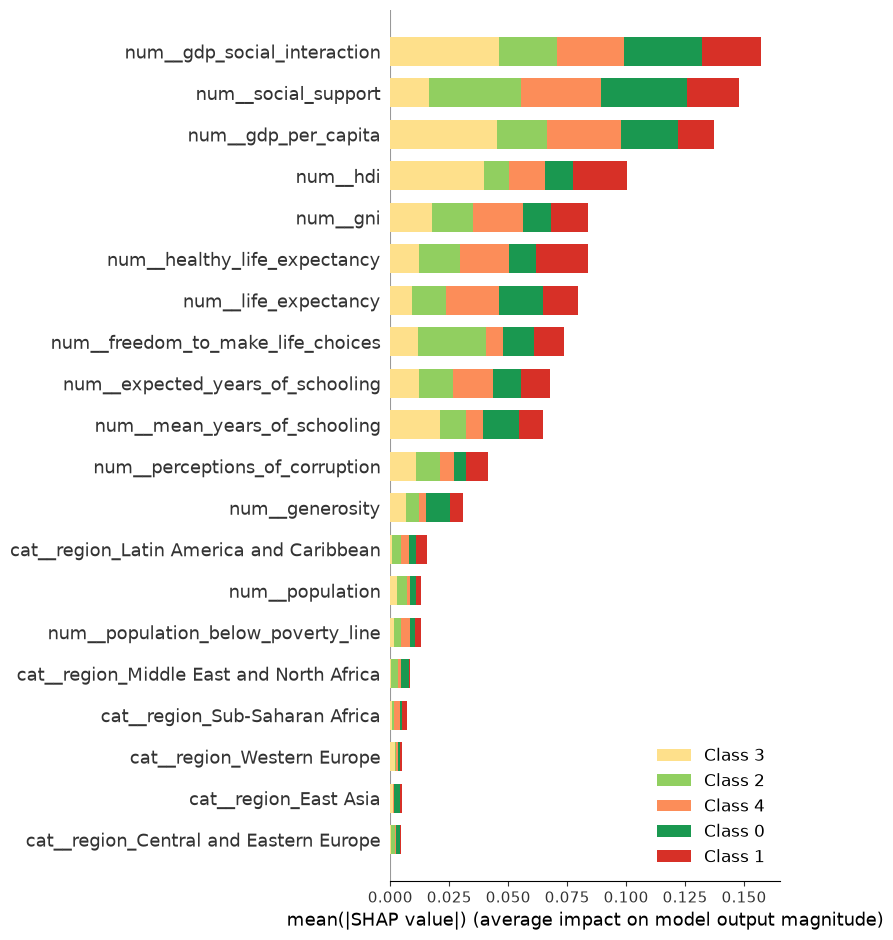

In [36]:
# Import necessary libraries
from matplotlib.colors import ListedColormap
import shap
import matplotlib.pyplot as plt

# Transform the test data using the fitted preprocessor
X_test_processed = preprocessor(X_test)
# (SHAP needs the same numeric feature matrix the model was trained on, not raw X_test)

# Get feature names matching the columns after preprocessing
feature_names = preprocess.get_feature_names_out()
# (Hint: preprocess.get_feature_names_out())

# Initialize SHAP explainer
# Define an explainer that will help us interpret the model's decisions
# (Hint: Use shap.Explainer with your best-performing tree-based model, e.g., the best Random Forest from GridSearchCV.
#  Note that the variable `model` was reassigned in Section 6, so be explicit about which model you explain.)
best_rf = grid.best_estimator_
explainer = shap.Explainer(best_rf, preprocessor(X_train), feature_names=feature_names)

# Compute SHAP values for the preprocessed test data
# This step generates Shapley values, which explain how each feature contributes to predictions
shap_values = explainer(X_test_processed)

# Generate SHAP summary plot
# This plot will show which features have the most impact on predictions
color_map = dict(zip(category_order, colors))
ordered_colors = [color_map[c] for c in best_rf.classes_]
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names, plot_type="bar", color=ListedColormap(ordered_colors))

# Your cell should output a SHAP summary plot showing the most important features.

### Explaining the Deep Learning Model

Deep learning models are often considered "black boxes" due to their complexity. Use SHAP to explain your model's predictions.

After applying SHAP, discuss:

- Does it provide a clear and sufficient explanation of how the model makes decisions?
- How easy or difficult is it to justify your model's predictions using this technique?

/var/folders/yw/0j97h26n0nq8lq5kwfb471w80000gn/T/ipykernel_53142/3967612129.py:13: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_nn, X_test_subset, feature_names=feature_names,


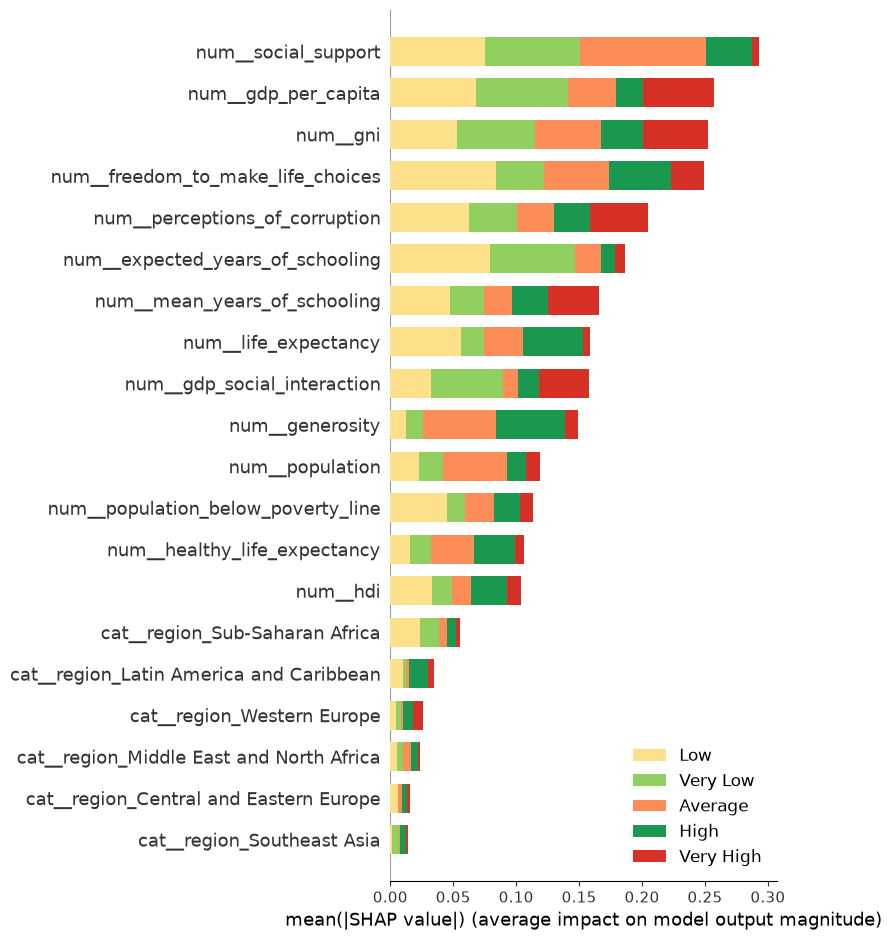

In [37]:
# Your lines of Code and Answer
# Wrap the Keras model's predict method as a plain function SHAP can call
def nn_predict(data):
    return keras_model.predict(data, verbose=0)

# Use a small background sample to keep computation manageable
background = preprocessor(X_train)[:20]
X_test_subset = X_test_processed[:15]

explainer_nn = shap.Explainer(nn_predict, background, feature_names=feature_names)
shap_values_nn = explainer_nn(X_test_subset)

shap.summary_plot(shap_values_nn, X_test_subset, feature_names=feature_names,
                   plot_type="bar", class_names=list(y_train_oh.columns), color=ListedColormap(ordered_colors))

SHAP gives us the attribution, which is useful and informative, but it still does not reconstruct the actual step-by-step computation through the network's layers.  

This Neural Network's SHAP summary plot indicates that `gdp_per_capita`, `social_support` and the interaction feature of these two are the most contributive factors in the model's prediction. This result is quite close to what we have observed in previous EDA section and Random Forest Models' SHAP analysis, which supports its reliability. Meanwhile, Region-related dummy variables only have a little impact.  

Therefore, applying SHAP makes it easier to discuss how much a variable changed/determined the model's prediction and how large proportion a paticular category has contributed.


### Experimentation

Test accuracy: 0.500

              precision    recall  f1-score   support

     Average       0.43      0.75      0.55         8
        High       0.29      0.25      0.27         8
         Low       0.33      0.25      0.29         8
   Very High       1.00      0.56      0.71         9
    Very Low       0.60      0.67      0.63         9

    accuracy                           0.50        42
   macro avg       0.53      0.49      0.49        42
weighted avg       0.54      0.50      0.50        42



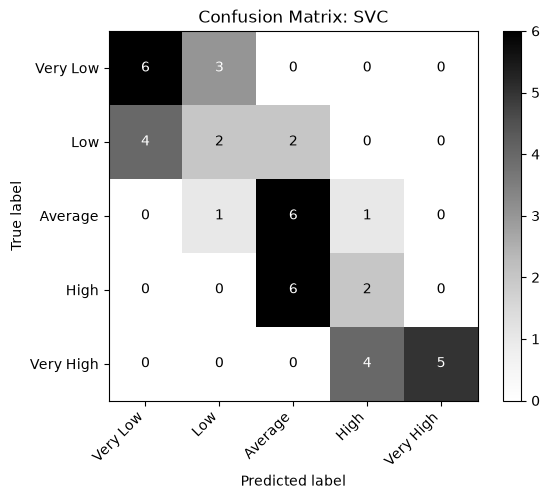

In [38]:
## You are encouraged to try more experimentation and any other models by adding more code cells to this notebook:
from sklearn.svm import SVC

model_svc = SVC(kernel='rbf', random_state=42)
model_svc.fit(preprocessor(X_train), y_train)

prediction_labels_svc = model_svc.predict(preprocessor(X_test))

print(f"Test accuracy: {accuracy_score(y_test, prediction_labels_svc):.3f}")
print()
print(classification_report(y_test, prediction_labels_svc))

cm = confusion_matrix(y_test, prediction_labels_svc, labels=category_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=category_order)
disp.plot(cmap='Greys')
plt.xticks(rotation=45, ha='right')
plt.title('Confusion Matrix: SVC')
plt.show()

## You can also try to import any new dataset pertaining to countries, merge it, and see if it helps the predictions.
## If it does not, try to explain why it wasn't helpful by exploring variable relationships.

---

## 9. Final Summary

Summarize your project in a few short paragraphs. Include:

- A table comparing the test performance of every model you trained
- Your best-performing model, its hyperparameters, and why you think it performed best
- The most important insights from your EDA and SHAP analysis
- Limitations of your approach and what you would try next

| Model                          | Key Hyperparameters                              | Test Accuracy |
|---------------------------------|--------------------------------------------------|---------------|
| Random Forest (Model 1)        | default                            |      0.595         |
| Random Forest (Model 2)        | n_estimators=200, max_depth=2, min_samples_leaf=2|     0.524          |
| Random Forest (Model 3, Grid)  | n_estimators=300, max_depth=4, min_samples_leaf=1|     0.524          |
| Neural Network (baseline)      | 128→64→64→32→5, relu, sgd, 300 epochs            |   0.595      |
| Neural Network (regularized)   | + Dropout(0.3), BatchNorm                        |   0.571      |
| KNN                            | n_neighbors=5                                    |   0.524     |
| SVC                             | kernel='rbf'                                     |   0.500    |


The best-performing models were tied between the unconstrained Random Forest (Model 1) and the baseline Neural Network, both reaching 0.595 test accuracy. The former one is possibily overfitting, making it not the best choice when predicting. Both used minimal constraints and relied directly on the strong signal already present in `gdp_per_capita`, `social_support`, and `related features`. Every attempt to further tune or regularize either approach (GridSearchCV, manual depth limits, Dropout/BatchNorm) or switch algorithms entirely (KNN, SVC) produced equal or worse accuracy, suggesting ~0.595 may represent close to a practical ceiling given our dataset's small size and inherently difficult classes.

Previous EDA identified `gdp_per_capita`, `hdi`, `gni`, and `social_support` as the strongest correlates of happiness (ρ≈0.8), while generosity showed essentially no correlation. I found significant multicollinearity among development indicators, since HDI is partly derived from them.   

SHAP confirmed `gdp_per_capita`, `social_support`, and the engineered interaction feature as consistently top-ranked across both Random Forest and Neural Network, validating the feature engineering. The two models diverged on mid-ranked features, illustrating how different architectures distribute importance across correlated features differently.

The most significant limitation is dataset size: only 137 countries means single train/test split results are quite noisy, as shown by our GridSearch-tuned model (0.524 test) scoring below the simpler default baseline (0.595), despite a better cross-validation score (0.589). The neural network results were also initially inconsistent across runs due to unseeded random weight initialization, while the reproducible seeded result (in trial) was a more modest ~0.570, underscoring how single-run deep learning results on small data can be misleading. Besides, the Low happiness category was consistently the hardest to classify across every model tested.   

Doable next steps will include repeating cross-validation for more reliable comparisons, coonducting ordinal-aware modeling instead of plain multiclass, and incorporating additional years of WHR data in current dataset.